In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from cartopy import crs, feature

In [2]:
fish = pd.read_csv('/Users/jvalenti/Downloads/d9372fc0-cb54-11f1-843d-bf963f88f5f1/fleet-monthly-csvs-10-v3-2023/fleet-monthly-csvs-10-v3-2023-01-01.csv',header=0,parse_dates=['date'])
Can = fish[(fish['flag']=='CAN') + (fish['flag']=='USA')]
mask_SS = (Can['cell_ll_lat']> 47) & (Can['cell_ll_lat']< 51) & (Can['cell_ll_lon']< -121) & (Can['cell_ll_lon']> -126)
SS = Can[mask_SS]
SS_active = SS[SS['fishing_hours']>0]

/Users/jvalenti/MOAD/analysis-jose/.pixi/envs/default/lib/python3.11/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


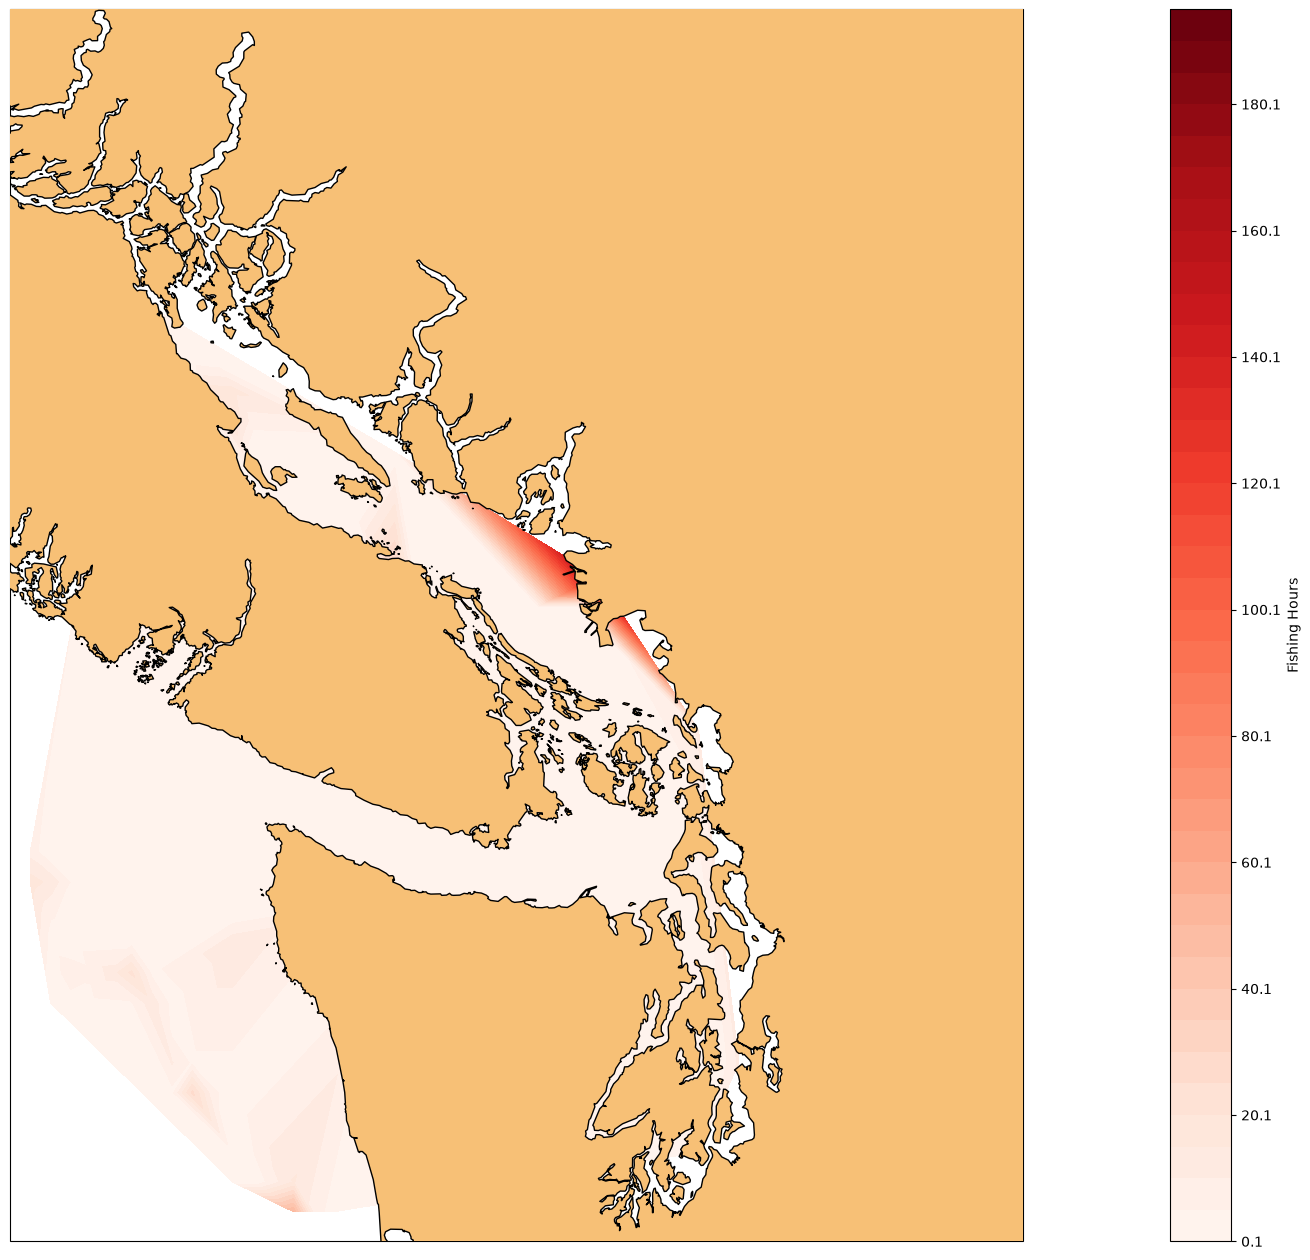

In [12]:
fig, ax = plt.subplots(figsize=(38, 16), subplot_kw={'projection': crs.Mercator()})
ax.set_extent([-126, -121, 47, 51], crs=crs.PlateCarree())
ax.add_feature(feature.GSHHSFeature('high', edgecolor='k', facecolor='#F7C076'),zorder=4)
#ax.add_feature(feature.OCEAN,zorder=1)


plt.tricontourf(SS_active['cell_ll_lon'], SS_active['cell_ll_lat'], SS_active['fishing_hours'], cmap='Reds',transform=crs.PlateCarree(),zorder=2,levels=np.arange(0.1, 200, 5))
plt.colorbar(label='Fishing Hours')